# 06 - Formation Water & Environmental Corrections

**Part A - Petrophys Curriculum**

Before we can turn a resistivity log into a water saturation, we need to know two
"invisible" properties of the well: **how salty the formation water is**
(captured by its resistivity `Rw`) and **how hot the rock is** (the temperature
profile). Both are temperature-dependent, and both feed directly into Archie's
equation in lesson 07.

This lesson derives, for well **30_6-5**:
1. the **temperature profile** from surface temperature + a bottom-hole
   temperature (BHT) gradient,
2. **mud filtrate resistivity `Rmf`** corrected to formation temperature,
3. **formation water resistivity `Rw`** by two independent routes - from salinity,
   and from the SP log,
4. an **invasion characterization** from the deep vs. shallow resistivity curves.


## Learning goals
- Build a **formation temperature profile** with
  `calculate_temperature_profile` from a surface temperature and a BHT, and read
  off the geothermal gradient.
- Correct a resistivity from measured to formation temperature with the **Arps
  relation** (`calculate_rmf`, `correct_rw_temperature`).
- Estimate **`Rw`** two ways - `rw_from_salinity` (and its inverse
  `salinity_from_rw`) and the **SP method** via `RwModule` - and understand when
  each is trustworthy.
- Characterize **invasion** from `RDEP` vs `RSHA`/`RMED` using
  `calculate_invasion_ratio` and `classify_invasion`.
- See exactly **why Rw and temperature are prerequisites** for the saturation
  calculation that follows in lesson 07.


## Why this matters
Archie's equation for water saturation is

$$S_w^{\,n} = \frac{a\,R_w}{\phi^{\,m}\,R_t}$$

Two of those inputs are *environmental*, not measured by a single log:

- **`Rw`** - the resistivity of the formation water. Fresh water is resistive,
  brine is very conductive; get `Rw` wrong and `Sw` is wrong by `Rw^(1/n)` - a
  2x error in `Rw` moves `Sw` by ~41 % for n=2.
- **Temperature** - resistivity of any brine falls as it heats up (ions move more
  freely). Both `Rw` and `Rmf` must be quoted *at formation temperature*, so we
  need the temperature at every depth.

Everything in this lesson exists to pin those two numbers down honestly.


### Prerequisites
This lesson assumes lessons **01-02** (loading a well, curve access). The
saturation math it feeds into is covered in **lesson 07**.

Teaching well: **30_6-5**. It carries `SP`, and the deep/medium/shallow
resistivity triplet `RDEP` / `RMED` / `RSHA` that we need for `Rw`-from-SP and for
invasion analysis. Note this LAS has **no** header `BHT`, `Rmf` or salinity, so we
supply sensible values explicitly and are transparent about it.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

well = read_las(petrophys.sample('30_6-5'))
print('well       :', well.name)
print('depth      : %.1f - %.1f %s' % (well.start_depth, well.stop_depth, well.depth_unit))
print('has SP / RDEP / RMED / RSHA :',
      well.has_curves(['SP', 'RDEP', 'RMED', 'RSHA']))

# What does the header actually give us? (spoiler: nothing environmental)
print('header BHT     :', well.header.bht)
for p in ['BHT', 'RMF', 'RM', 'RW', 'SALINITY']:
    print('  parameter %-9s:' % p, well.get_parameter(p))

petrophys 0.1.0


well       : 30/6-5
depth      : 176.6 - 3556.1 m
has SP / RDEP / RMED / RSHA : True
header BHT     : None
  parameter BHT      : None
  parameter RMF      : None
  parameter RM       : None
  parameter RW       : None
  parameter SALINITY : None


## 1. Temperature profile from surface temp + BHT

Formation temperature is assumed to rise linearly with depth:

`T(depth) = T_surface + gradient * depth`

Given a surface temperature and a bottom-hole temperature (BHT) at total depth,
`calculate_temperature_profile` fits the gradient and evaluates `T` at every log
sample. Because this LAS has no header BHT, we pass one explicitly: a ~60 F
surface reference temperature and a BHT of 250 F at TD.


In [2]:
from petrophys.interpretation.temperature import (
    calculate_temperature_profile,
    calculate_temperature_gradient,
)
from petrophys.interpretation.temperature.temp_gradient import gradient_to_celsius_per_km

SURFACE_T_F = 60.0     # generic ~60 F surface reference (the North Sea seabed
                       # itself is nearer 40 F; a linear anchor is all we need)
BHT_F       = 250.0    # bottom-hole temperature at TD
TD          = well.bottom   # total depth in metres (well.depth_unit == 'm')

temp_result = calculate_temperature_profile(
    well,
    bht=BHT_F,
    surface_temp=SURFACE_T_F,
    bht_unit='F',
    surface_temp_unit='F',
    td=TD,
    depth_unit='m',
)
temp = temp_result.temperature   # degF, one value per depth sample

print('source        :', temp_result.source)
print('surface temp  : %.1f F' % temp_result.surface_temp)
print('gradient      : %.3f F/100ft  (%.1f C/km)'
      % (temp_result.gradient, gradient_to_celsius_per_km(temp_result.gradient)))
print('T range       : %.1f - %.1f F over the logged section'
      % (np.nanmin(temp), np.nanmax(temp)))

# The convenience gradient helper reproduces the same slope from two points:
g = calculate_temperature_gradient(SURFACE_T_F, 0.0, BHT_F, TD,
                                   temp_unit='F', depth_unit='m')
print('cross-check gradient (two-point) : %.3f F/100ft' % g)

source        : linear_gradient_from_BHT
surface temp  : 60.0 F
gradient      : 1.629 F/100ft  (29.7 C/km)
T range       : 69.4 - 250.0 F over the logged section
cross-check gradient (two-point) : 1.629 F/100ft


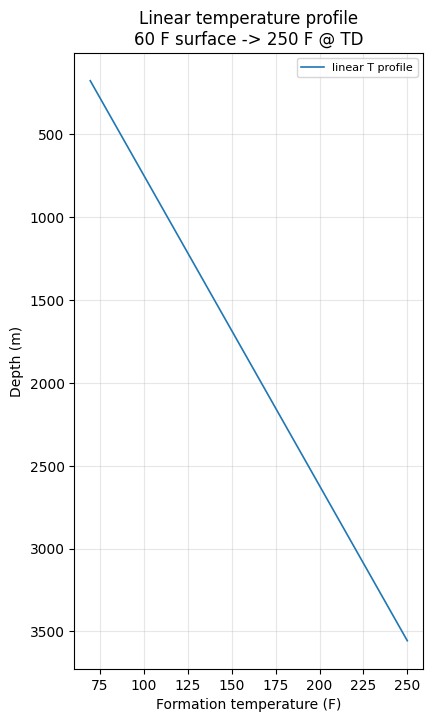

In [3]:
# Temperature-vs-depth profile via the library line-comparison helper
# (x = temperature, series = depth, invert_yaxis so depth increases downward).
from petrophys.visualization import create_line_comparison

fig, ax = create_line_comparison(
    temp, {'linear T profile': well.depth},
    xlabel='Formation temperature (F)', ylabel='Depth (%s)' % well.depth_unit,
    invert_yaxis=True, figsize=(4.5, 8),
    title='Linear temperature profile\n%.0f F surface -> %.0f F @ TD'
          % (SURFACE_T_F, BHT_F))
plt.show()


#### Temperature context

A gradient near 1.6 F/100 ft, or about 30 C/km, is typical of many sedimentary
basins. The depth-dependent temperature array provides the reference
temperature for Rmf and Rw.


## 2. Mud filtrate resistivity `Rmf` at formation temperature

While drilling, mud filtrate invades the near-wellbore rock. Its resistivity
`Rmf` is normally reported at a **surface / measured** temperature, but we need it
at *formation* temperature. Resistivity scales with temperature through the
**Arps relation**:

$$R_2 = R_1 \cdot \frac{T_1 + 6.77}{T_2 + 6.77}\quad(T \text{ in }^{\circ}F)$$

`calculate_rmf` applies exactly this. We give it an `Rmf` of 0.6 ohm.m measured at
75 F and correct it to the depth-varying formation temperature.


In [4]:
from petrophys.interpretation.electrical import calculate_rmf

RMF_SURFACE = 0.6    # ohm.m at the measured temperature
RMF_TEMP_F  = 75.0   # measured temperature

rmf = calculate_rmf(
    rmf_surface=RMF_SURFACE,
    temp_measured=RMF_TEMP_F,
    temp_formation=temp,      # array -> Rmf becomes depth-varying
)

print('Rmf @ 75 F (surface) : %.3f ohm.m' % RMF_SURFACE)
print('Rmf @ formation T    : %.3f - %.3f ohm.m (shallow -> deep)'
      % (np.nanmax(rmf), np.nanmin(rmf)))
print('-> Rmf drops with depth because the rock gets hotter and brine conducts')
print('   more easily. Always correct resistivities to formation T before use.')

# A representative single value for the zone of interest (median of the profile):
rmf_zone = float(np.nanmedian(rmf))
print('median Rmf used below : %.3f ohm.m' % rmf_zone)

Rmf @ 75 F (surface) : 0.600 ohm.m
Rmf @ formation T    : 0.644 - 0.191 ohm.m (shallow -> deep)
-> Rmf drops with depth because the rock gets hotter and brine conducts
   more easily. Always correct resistivities to formation T before use.
median Rmf used below : 0.295 ohm.m


## 3. Formation water resistivity `Rw`

`Rw` is the star input. We derive it two independent ways.

### 3a. From salinity (if you know / assume the water salinity)
`rw_from_salinity` uses the Schlumberger empirical NaCl relation, corrected to
temperature with Arps. Its inverse, `salinity_from_rw`, lets you sanity-check any
`Rw` you obtain by another method by converting it back to an equivalent salinity.


In [5]:
from petrophys.interpretation.electrical.rw.salinity_rw import (
    rw_from_salinity, salinity_from_rw, classify_water_salinity,
)

# Formation temperature at a mid-reservoir depth, say 2900 m:
z_ref = 2900.0
i_ref = int(np.nanargmin(np.abs(well.depth - z_ref)))
T_ref = float(temp[i_ref])
print('reference depth %.0f m -> T = %.1f F' % (z_ref, T_ref))

print()
print('%-12s %-10s %-12s' % ('salinity(ppm)', 'Rw(ohm.m)', 'class'))
for sal in [10000, 35000, 70000, 150000]:
    rw = float(rw_from_salinity(sal, T_ref))
    print('%-12d %-10.4f %-12s' % (sal, rw, classify_water_salinity(sal)))

# Pick a North Sea-like formation-brine salinity and take its Rw as our estimate:
SALINITY_PPM = 35000.0
rw_from_sal = float(rw_from_salinity(SALINITY_PPM, T_ref))
print()
print('assumed salinity %.0f ppm -> Rw = %.4f ohm.m @ %.0f F'
      % (SALINITY_PPM, rw_from_sal, T_ref))
print('inverse check: salinity_from_rw(%.4f) = %.0f ppm'
      % (rw_from_sal, salinity_from_rw(rw_from_sal, T_ref)))

reference depth 2900 m -> T = 214.9 F

salinity(ppm) Rw(ohm.m)  class       
10000        0.2081     saline      
35000        0.0661     saline      
70000        0.0363     saline      
150000       0.0199     brine       

assumed salinity 35000 ppm -> Rw = 0.0661 ohm.m @ 215 F
inverse check: salinity_from_rw(0.0661) = 35000 ppm


### 3b. From the SP log

Where a saline formation sits opposite a fresher mud filtrate, the SP deflects.
The static SP (SSP) relates `Rmf` and `Rw`:

`SSP = -K * log10(Rmf / Rw)`, with `K = 61 + 0.133 * T` (T in degF)

`RwModule` automates the hard part: it picks clean-sand and shale SP baselines
from the log itself, computes SSP, and inverts for `Rw`. It needs `Rmf` (at
formation T) and the temperature we already built.

One bookkeeping subtlety: the module inverts the SP equation depth by depth with
the depth-varying temperature and returns the **median** `Rw` - so that number
lives at the **median profile temperature** (recorded in the result metadata as
`rw_temperature_f`), *not* at our 2900 m reference temperature. Before comparing
it with the salinity-based estimate we Arps-shift it to `T_ref`. Comparing
resistivities quoted at different temperatures is exactly the mistake this
lesson exists to prevent.


In [6]:
from petrophys.interpretation.electrical.rw import RwModule
from petrophys.interpretation.electrical.rw.temp_correction import correct_rw_temperature

rw_module = RwModule(method='sp')
rw_result = rw_module.calculate(well, rmf=rmf_zone, temperature=temp)

print('method       :', rw_result.method)
print('n clean pts  :', rw_result.n_points)
print('SP clean line: %.1f mV' % rw_result.metadata['sp_clean_mv'])
print('SP shale line: %.1f mV' % rw_result.metadata['sp_shale_mv'])
print('SSP          : %.1f mV' % rw_result.metadata['ssp_mv'])

# The returned Rw is the median over the clean intervals, so it corresponds to
# the MEDIAN profile temperature (metadata 'rw_temperature_f') - not to T_ref.
# Arps-shift it to T_ref so all Rw numbers in this lesson share one basis.
rw_sp_raw  = float(rw_result.rw)
T_sp       = float(rw_result.metadata['rw_temperature_f'])
rw_from_sp = float(correct_rw_temperature(rw_sp_raw, from_temp=T_sp, to_temp=T_ref))

print()
print('Rw (SP, as returned)   : %.4f ohm.m @ %.0f F (median profile temperature)'
      % (rw_sp_raw, T_sp))
print('Rw (SP, Arps -> T_ref) : %.4f ohm.m @ %.0f F' % (rw_from_sp, T_ref))
print('equivalent salinity of the SP-derived Rw : %.0f ppm'
      % salinity_from_rw(rw_from_sp, T_ref))

method       : sp_clean_water
n clean pts  : 7760
SP clean line: 32.3 mV
SP shale line: 77.5 mV
SSP          : -45.2 mV

Rw (SP, as returned)   : 0.0831 ohm.m @ 160 F (median profile temperature)
Rw (SP, Arps -> T_ref) : 0.0624 ohm.m @ 215 F
equivalent salinity of the SP-derived Rw : 37328 ppm


### 3c. Reconcile the two estimates

Two independent methods should land in the same ballpark - **once both are quoted
at the same temperature**. If they do, we gain confidence; if not, one of the
assumptions (salinity guess, SP baselines, mud system) is off.


In [7]:
compare = pd.DataFrame({
    'method': ['from salinity (%.0f ppm)' % SALINITY_PPM,
               'from SP log (Arps -> %.0f F)' % T_ref],
    'Rw (ohm.m)': [rw_from_sal, rw_from_sp],
    'equiv. salinity (ppm)': [SALINITY_PPM,
                              float(salinity_from_rw(rw_from_sp, T_ref))],
})
print(compare.to_string(index=False))

ratio = max(rw_from_sal, rw_from_sp) / min(rw_from_sal, rw_from_sp)
print()
print('agreement factor : %.2fx  (Sw impact for n=2: ~%.0f %%)'
      % (ratio, 100 * (np.sqrt(ratio) - 1.0)))
print('Remember the stakes: Sw scales with Rw^(1/n), so a 2x Rw error moves Sw by')
print('~41 % for n=2. Two Rw estimates within ~25-30 % of each other are')
print('comfortable; past a factor of ~2, revisit the salinity assumption or the')
print('SP baselines before doing any saturation work. Here the two routes agree')
print('within ~6 %, and the SP-derived equivalent salinity (~37,000 ppm) sits')
print('close to the 35,000 ppm we assumed. Two independent routes, one story.')

# We will carry the SP-derived Rw (quoted at T_ref) forward as the "log-based"
# estimate.
RW = rw_from_sp
print()
print('Rw carried to saturation (lesson 07) : %.4f ohm.m @ %.0f F' % (RW, T_ref))

                     method  Rw (ohm.m)  equiv. salinity (ppm)
  from salinity (35000 ppm)    0.066083           35000.000000
from SP log (Arps -> 215 F)    0.062412           37328.337643

agreement factor : 1.06x  (Sw impact for n=2: ~3 %)
Remember the stakes: Sw scales with Rw^(1/n), so a 2x Rw error moves Sw by
~41 % for n=2. Two Rw estimates within ~25-30 % of each other are
comfortable; past a factor of ~2, revisit the salinity assumption or the
SP baselines before doing any saturation work. Here the two routes agree
within ~6 %, and the SP-derived equivalent salinity (~37,000 ppm) sits
close to the 35,000 ppm we assumed. Two independent routes, one story.

Rw carried to saturation (lesson 07) : 0.0624 ohm.m @ 215 F


## 4. Invasion characterization (RDEP vs RSHA / RMED)

Resistivity tools read at different depths of investigation. Comparing a **deep**
curve (`RDEP`, reads the true, uninvaded formation `Rt`) with a **shallow** curve
(`RSHA`, reads the flushed zone `Rxo`) tells us about invasion and, indirectly,
about movable hydrocarbons.

The **invasion ratio** is `Rxo / Rt`:

- **ratio < 0.8 - conductive invasion:** filtrate more conductive than the pore
  fluid; often a hint of hydrocarbons in the uninvaded zone.
- **0.8 <= ratio <= 1.2 - minimal invasion:** little contrast (`Rmf` ~ `Rw`).
- **ratio > 1.2 - resistive invasion:** filtrate more resistive; typical of very
  saline formation water.

We window in on 2350-2950 m, where the story is clearest. This is the display
industry composites use: the separation between the deep and shallow curves,
shaded and labeled on the resistivity track itself (gold = shallow above deep,
fresh-filtrate invasion; green = shallow below deep, the moveable-hydrocarbon
hint). The Rxo/Rt ratio stays a computed diagnostic behind the classification
statistics; composites do not carry it as a separate track.

In [8]:
from petrophys.interpretation.electrical import calculate_invasion_ratio, classify_invasion

rsha = well.get('RSHA').data   # shallow  -> Rxo (flushed zone)
rmed = well.get('RMED').data   # medium
rdep = well.get('RDEP').data   # deep     -> Rt  (true formation)

ratio = calculate_invasion_ratio(rsha, rdep)   # Rxo / Rt, invalid samples -> NaN
finite = np.isfinite(ratio)
print('invasion ratio: %d valid / %d samples' % (int(finite.sum()), len(ratio)))
print('median ratio  : %.2f' % np.nanmedian(ratio))

# Fraction of the well in each invasion regime
cls = classify_invasion(ratio[finite])          # array of enum members
values = np.array([c.value for c in cls])
for label in ['conductive', 'minimal', 'resistive']:
    pct = 100.0 * np.mean(values == label)
    print('  %-11s : %5.1f %%' % (label, pct))

invasion ratio: 22079 valid / 22176 samples
median ratio  : 1.19
  conductive  :  18.4 %
  minimal     :  32.3 %
  resistive   :  49.2 %


In [9]:
from petrophys.interpretation.electrical.invasion import InvasionModule

# The high-level module does the same and returns tidy statistics, and it will
# fall back to RMED as a shallow proxy where RSHA is missing.
inv = InvasionModule(rxo_curve='RSHA', rt_curve='RDEP')
inv_result = inv.analyze(well)
s = inv_result.statistics
print('curves used   : Rxo=%s  Rt=%s' % (s['rxo_curve'], s['rt_curve']))
print('mean ratio    : %.2f   median : %.2f' % (s['mean_ratio'], s['median_ratio']))
print('conductive    : %.1f %%' % s['conductive_percent'])
print('minimal       : %.1f %%' % s['minimal_percent'])
print('resistive     : %.1f %%' % s['resistive_percent'])

curves used   : Rxo=RSHA+RMED  Rt=RDEP
mean ratio    : 1.35   median : 1.19
conductive    : 18.4 %
minimal       : 32.6 %
resistive     : 49.0 %


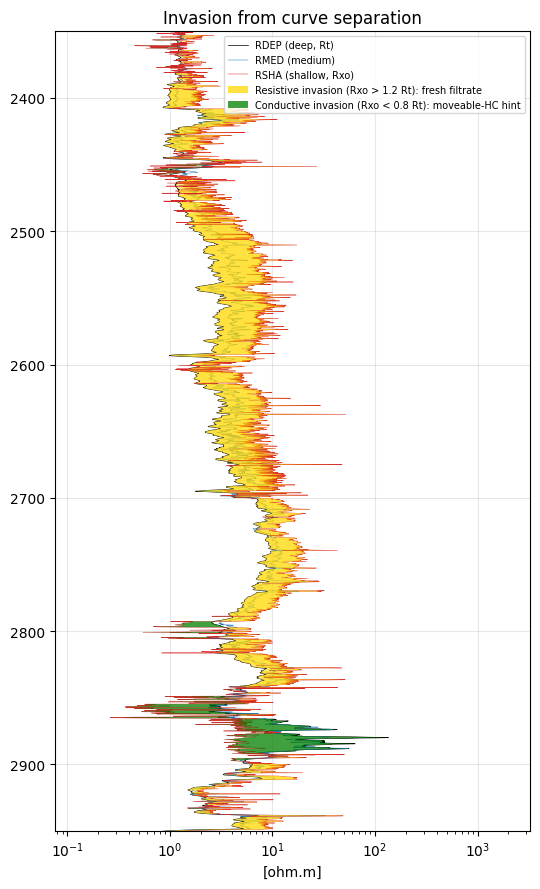

In [10]:
# The industry display for invasion: the resistivity triplet with the
# deep-vs-shallow SEPARATION shaded and labeled. The Rxo/Rt ratio itself is a
# computed diagnostic (it drives the classification statistics above); it is
# not shown as a track because composites do not carry one - interpreters read
# the shaded separation directly.
from petrophys.visualization import LogPlot
from matplotlib.patches import Patch

lp = LogPlot(well, figsize=(5.5, 9))
lp.create_figure(n_tracks=1)

lp.add_curve(0, 'RDEP', color='black',    linewidth=0.5, log_scale=True,
             label='RDEP (deep, Rt)')
lp.add_curve(0, 'RMED', color='tab:blue', linewidth=0.35, log_scale=True,
             label='RMED (medium)')
lp.add_curve(0, 'RSHA', color='tab:red',  linewidth=0.35, log_scale=True,
             label='RSHA (shallow, Rxo)')

# Shade only MEANINGFUL separation (the same 0.8x / 1.2x bands the numeric
# classification uses) so the profile reads as bands, not noise.
_d  = well.depth
_rd = well.get('RDEP').data
_rs = well.get('RSHA').data
_ok = np.isfinite(_rd) & np.isfinite(_rs)
lp.axes[0].fill_betweenx(_d, _rs, _rd, where=_ok & (_rs < 0.8 * _rd),
                         color='green', alpha=0.75, linewidth=0, zorder=3)
lp.axes[0].fill_betweenx(_d, _rs, _rd, where=_ok & (_rs > 1.2 * _rd),
                         color='gold', alpha=0.75, linewidth=0, zorder=3)

# Label the fills so the figure explains itself.
handles, labels = lp.axes[0].get_legend_handles_labels()
handles += [Patch(facecolor='gold', alpha=0.75),
            Patch(facecolor='green', alpha=0.75)]
labels  += ['Resistive invasion (Rxo > 1.2 Rt): fresh filtrate',
            'Conductive invasion (Rxo < 0.8 Rt): moveable-HC hint']
lp.axes[0].legend(handles, labels, loc='upper right', fontsize=7)

lp.axes[0].set_title('Invasion from curve separation')
# Window in on the clearest section: resistive flushing through the wet sands,
# then conductive separation over the Baat reservoir top (~2841 m).
lp.set_depth_range(2350.0, 2950.0)
lp.show()


#### Reading the invasion track

Where shallow resistivity is below deep resistivity, shown by green shading and
$R_{xo}/R_t < 0.8$, the flushed zone is more conductive than the uninvaded
formation. This is consistent with invasion replacing some hydrocarbons with
conductive filtrate, and the green interval aligns with the Baat reservoir top
near 2841-2890 m.

Gold shading marks $R_{xo}/R_t > 1.2$, the opposite response, which dominates
this mostly water-bearing well. The numerical invasion classification uses the
same ratio limits.


## 5. How this feeds the saturation calculation

Pulling it together, lesson 07's Archie/Simandoux call will need:

| input | where it came from here |
|---|---|
| **`Rw`** at formation T | SP method, Arps-shifted to the reference T (cross-checked against salinity) |
| **formation temperature** | linear BHT profile -> `temp` array |
| **`Rmf`** at formation T | Arps-corrected from surface `Rmf` |
| **`Rt`** | deep resistivity `RDEP` |
| invasion context | `Rxo/Rt` ratio, to know where filtrate matters |

Without a temperature-consistent `Rw`, the saturation numbers are meaningless -
that is why this environmental step comes *before* saturation, not after.


In [11]:
summary = pd.DataFrame({
    'quantity': ['surface temperature', 'BHT (at TD)', 'geothermal gradient',
                 'Rmf @ formation T (median)', 'Rw (from SP, at ref. T)',
                 'Rw (from %.0fk ppm)' % (SALINITY_PPM / 1000),
                 'reference temperature', 'median invasion ratio'],
    'value': ['%.0f F' % SURFACE_T_F, '%.0f F' % BHT_F,
              '%.2f F/100ft' % temp_result.gradient,
              '%.3f ohm.m' % rmf_zone, '%.4f ohm.m' % rw_from_sp,
              '%.4f ohm.m' % rw_from_sal, '%.0f F' % T_ref,
              '%.2f' % np.nanmedian(ratio)],
})
print(summary.to_string(index=False))

                  quantity        value
       surface temperature         60 F
               BHT (at TD)        250 F
       geothermal gradient 1.63 F/100ft
Rmf @ formation T (median)  0.295 ohm.m
   Rw (from SP, at ref. T) 0.0624 ohm.m
         Rw (from 35k ppm) 0.0661 ohm.m
     reference temperature        215 F
     median invasion ratio         1.19


## Pitfalls & parameter choices
- **Temperature drives resistivity.** Every `Rw`/`Rmf` must be quoted at formation
  temperature. A wrong gradient shifts `Rw` and hence `Sw` systematically.
- **The SP method fails in shale, fresh water, or KCl/oil-based mud.** It assumes
  a clean, saline sand opposite a fresher filtrate. Check the SSP magnitude - a
  few mV of deflection cannot support a reliable `Rw`.
- **Salinity is often a guess.** If you have a produced-water analysis or an
  offset well `Rw`, prefer it. `salinity_from_rw` is handy to translate any `Rw`
  back into an intuitive salinity for a gut check.
- **Invasion ratio needs true shallow/deep curves.** With only `RMED` as a proxy
  the contrast is muted; the module flags when it falls back to a medium proxy.
- **OBM has no `Rmf`.** Oil-based mud does not conduct; the SP/`Rmf` workflow does
  not apply and you fall back to a known or offset `Rw`.


## Recap
- A **linear temperature profile** from surface T + BHT gives formation
  temperature at every depth - the backbone for all resistivity corrections.
- **Arps** rescales resistivity between temperatures; `calculate_rmf` uses it to
  put `Rmf` on a formation-temperature footing, and `correct_rw_temperature`
  moves the SP-derived `Rw` onto the same basis before any comparison.
- **`Rw`** can be had from **salinity** or from the **SP log**; quoted at the
  same temperature, agreement between the two is your confidence check.
  `salinity_from_rw` closes the loop.
- The **invasion ratio** `Rxo/Rt` from `RDEP` vs `RSHA` classifies each depth as
  conductive / minimal / resistive invasion and flags permeable, possibly
  hydrocarbon-bearing zones.
- All of this exists to hand a temperature-consistent **`Rw`** (and `Rt`, `T`) to
  the **saturation** calculation in lesson 07.


## Try it yourself
> **Exercise 1.** Rerun the temperature profile with a hotter BHT (e.g. 300 F).
> How much does the SP-derived `Rw` move, and why? (Hint: `K = 61 + 0.133*T`.)
>
> **Exercise 2.** Sweep assumed salinity from 20k to 120k ppm and plot
> `rw_from_salinity` vs salinity at `T_ref`. Where does it match the SP `Rw`? That
> intersection is your salinity estimate.
>
> **Exercise 3.** Use `InvasionModule.add_to_well(well)` to attach an `INV_RATIO`
> curve, then colour the resistivity track by invasion class. Do the conductive
> streaks line up with the low-GR sands from lesson 05?


## What's next
Part A continues. In **07 - Water Saturation** we combine everything - clay
volume, porosity, the mineral model, and the `Rw`/temperature derived here - to
compute **water saturation**; **08 - Permeability** and **09 - Reservoir Quality
& Net Pay** then finish Part A.
